# A dynamic hydrocracker, and the reformer's recycle loop

`difflow_refinery.dynamic.DynamicHydrocracker` runs a solved steady `Hydrocracker` in time: its pretreat and cracking beds as cells with gas, liquid and catalyst holdup, the cracking quench valves as integral controllers on each bed's inlet temperature (what the steady unit's solved quench stands for), the HP separator's level, the recycle loop's gas inventory, and the fractionator behind product holdups -- whose UCO holdup carries the UCO recycle, so neither of the steady unit's tears is solved. Its rest state is the steady unit's answer (see the gates in `docs/unit-operations-refinery.md`, "Dynamic operation").

This notebook: build it on a straight-run VGO and settle it; move the cracking inlets the way an operator does (a bounded ramp) and take a gradient through that move; lose half the recycle compressor; probe the margin to runaway; show the one transient that still does not integrate (a full compressor trip); then the catalytic reformer with its dynamic separator and recycle loop through a partial compressor trip.

Every holdup and time constant is ILLUSTRATIVE (`HydrocrackerHoldupParams`): the transients have not been compared with a plant or a published dynamic model. Run time: about an hour and a half on a laptop CPU, most of it the gradient.

In [1]:
import time, warnings
import jax, jax.numpy as jnp, numpy as np
import matplotlib.pyplot as plt
jax.config.update("jax_enable_x64", True)

import difflow_refinery as dr
from difflow_refinery.hydrocracking.unit import Hydrocracker, HydrocrackerParams
from difflow_refinery.hydrotreating.feed import select_cuts, straight_run_cut
from difflow_refinery.dynamic import DynamicHydrocracker, DynamicRunawayWarning, DynamicReformerTrain

def vgo(sg=0.86, sulfur=1.8, nitrogen=1500.0):
    a = dr.Assay([5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 95],
                 jnp.asarray([t + 273.15 for t in (60, 95, 150, 205, 260, 315, 370, 430, 500, 600, 680)]),
                 sg=sg, light_ends={"propane": 0.5, "n_butane": 1.0, "n_pentane": 1.5},
                 heavy_end=dr.HeavyEnd(), sulfur_wt=sulfur, nitrogen_wppm=nitrogen)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        char = dr.characterize(a, composition=True)
    return char, straight_run_cut(char, rate=50.0, cuts=select_cuts(char, 370 + 273.15, 560 + 273.15))

## 1. The steady unit and its dynamic twin

A 370-560 C straight-run VGO of the docs' light crude, 50 kg/s, once through, at the default specs (cracking inlets 380 C, quench solved for them).

In [2]:
char, feed = vgo()
unit = Hydrocracker(char, feed, HydrocrackerParams())
t0 = time.time()
steady = unit.solve(feed)
print(f"steady solve {time.time() - t0:.0f} s (mostly compile)")
print(steady.table())

t0 = time.time()
dyn = DynamicHydrocracker.from_steady(unit, feed, steady)          # 5 cells per bed, 3 RK4 steps per cell
y_rest = dyn.settle(2 * 3600.0)
print(f"\n{dyn.y0.size} states; built and settled for 2 h in {time.time() - t0:.0f} s")
ob, ref = dyn.observe(0.0, y_rest), dyn.steady_reference()
for k in ("conversion.per_pass", "wabt.pretreat", "wabt.crack", "h2.makeup", "recycle.rate"):
    print(f"{k:22s} dynamic {float(ob[k]):12.5f}   steady {float(ref[k]):12.5f}")
print("quench valves (fraction of the treat gas):", np.round(np.asarray(ob["crack.quench"]), 5),
      " steady:", np.round(np.asarray(ref["crack.quench"]), 5))

steady solve 47 s (mostly compile)
conversion (370 C+): per pass 69.0 %, overall 69.0 %; UCO recycle 0.00 kg/s
WABT pretreat 400.3 C (dT 47.4 K), cracking 395.0 C (dT 115.7 K); organic N to cracker 0.0 wppm
yields (wt% fresh feed): off_gas 1.07, lpg 1.24, light_naphtha 2.56, heavy_naphtha 10.47, kerosene 24.76, diesel 29.12, uco_bleed 31.02
H2: chemical 277 Nm3/m3 (1646 scf/bbl, 2.69 wt%), makeup 354 Nm3/m3
kerosene SG 0.7892; diesel SG 0.8376, cetane index 66.0, S 0.0 wppm; UCO BMCI 32.9



20221 states; built and settled for 2 h in 283 s


conversion.per_pass    dynamic      0.68980   steady      0.68980
wabt.pretreat          dynamic    673.47895   steady    673.47897
wabt.crack             dynamic    668.16898   steady    668.16900
h2.makeup              dynamic    851.76971   steady    851.77012
recycle.rate           dynamic   2870.32448   steady   2870.32412
quench valves (fraction of the treat gas): [0.16477 0.16945 0.15913 0.15198]  steady: [0.16477 0.16945 0.15913 0.15198]


## 2. An operator move: +5 K on the cracking inlets at 5 K/h

A reactor temperature is moved at a bounded rate, a few K per hour, so the exotherm can be watched as it develops (`OPERATOR_RAMP_K_PER_H`, an assumption). `dyn.move` turns a setpoint change into a smoothstep no faster than that rate; the interstage exchanger and the quench controllers follow it.

312 s, 558 steps, completed True


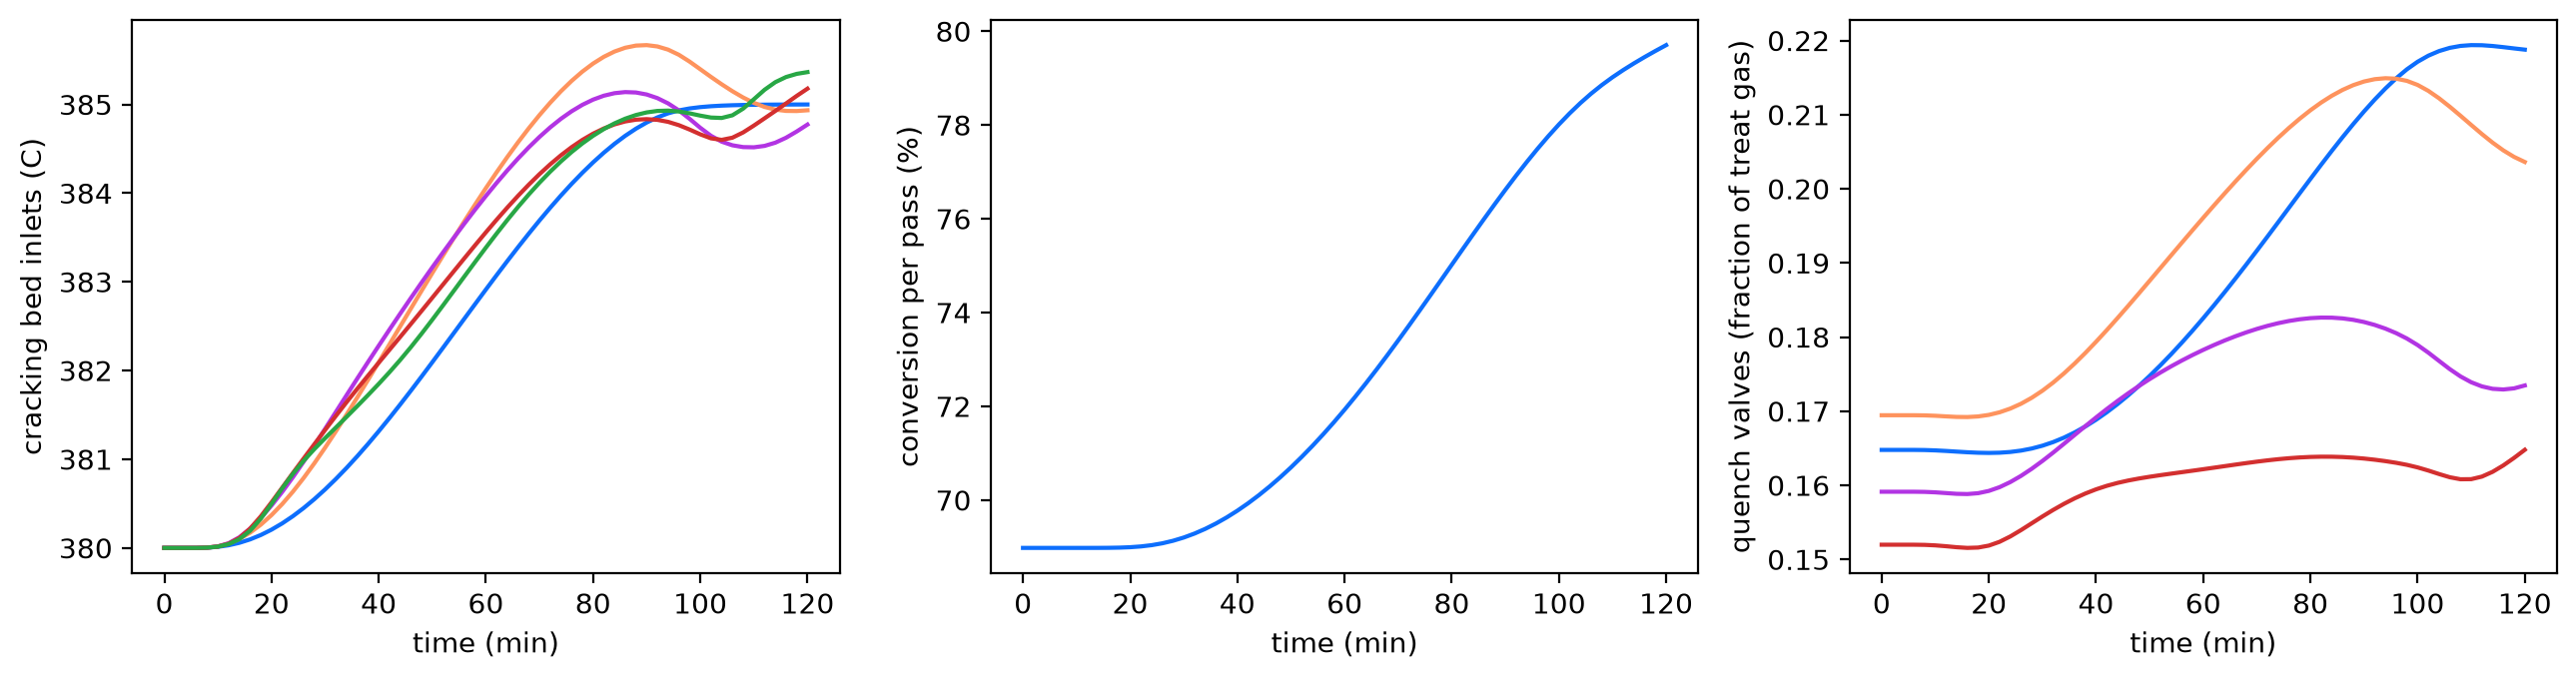

In [3]:
steps, ramp = dyn.move("T_crack", 5.0, max_rate_K_per_h=5.0)
a = dyn.args(steps=steps, ramp=ramp)
t0 = time.time()
sim = dyn.simulate(2 * 3600.0, args=a, y0=y_rest, n_save=61)
tr = dyn.trajectory(sim, a, ["conversion.per_pass", "T_max", "crack.T_in", "crack.quench", "h2.makeup"])
print(f"{time.time() - t0:.0f} s, {int(sim.info.n_steps)} steps, completed {bool(sim.info.success)}")
t = np.asarray(tr["t"]) / 60
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(t, np.asarray(tr["crack.T_in"]) - 273.15); ax[0].set_ylabel("cracking bed inlets (C)")
ax[1].plot(t, 100 * np.asarray(tr["conversion.per_pass"])); ax[1].set_ylabel("conversion per pass (%)")
ax[2].plot(t, np.asarray(tr["crack.quench"])); ax[2].set_ylabel("quench valves (fraction of treat gas)")
for a_ in ax: a_.set_xlabel("time (min)")
fig.tight_layout()

## 3. A gradient through the move

d(conversion one hour into the move)/d(size of the move), by reverse mode through the diffrax solve, against central differences. The scenario is smooth, so the finite differences converge.

In [4]:
from difflow_refinery.dynamic.signals import ramp_for_rate
R = lambda **kw: {**{k: 60.0 for k in dyn.base_signals}, **kw}

def conv_at_1h(d):
    a = dyn.args(steps={"T_crack": [(300.0, d)]}, ramp=R(T_crack=ramp_for_rate(5.0, 5.0 / 3600)))
    s = dyn.simulate(3600.0, args=a, y0=y_rest, n_save=2, warn=False)
    return dyn.observe(s.trajectory.t[-1], s.y_final, a)["conversion.per_pass"]

t0 = time.time()
g = float(jax.grad(conv_at_1h)(jnp.asarray(5.0)))
print(f"reverse mode: {g:.8e} per K ({time.time() - t0:.0f} s with compile)")
h = 0.5
fd = (float(conv_at_1h(jnp.asarray(5.0 + h))) - float(conv_at_1h(jnp.asarray(5.0 - h)))) / (2 * h)
print(f"central difference (h = {h} K): {fd:.8e}; relative difference {abs(g - fd) / abs(fd):.1e}")

E1030 16:41:34.611779 185447002 slow_operation_alarm.cc:73] 
********************************
[Compiling module jit_diffeqsolve for CPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


E1030 16:57:04.624321 185446906 slow_operation_alarm.cc:140] The operation took 17m30.021019s

********************************
[Compiling module jit_diffeqsolve for CPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


reverse mode: 6.17057657e-03 per K (3652 s with compile)


central difference (h = 0.5 K): 6.17091999e-03; relative difference 5.6e-05


## 4. Losing half the recycle compressor

The compressor falls to half its capacity over a minute (one of two machines, or a speed fallback); the console answers by cutting the cracking setpoint 10 K at an emergency rate of 30 K/h. With less treat gas the pretreat bed's hydrogen partial pressure falls and its nitrogen slip rises; the cut brings the beds back.

276 s, 304 steps, completed True


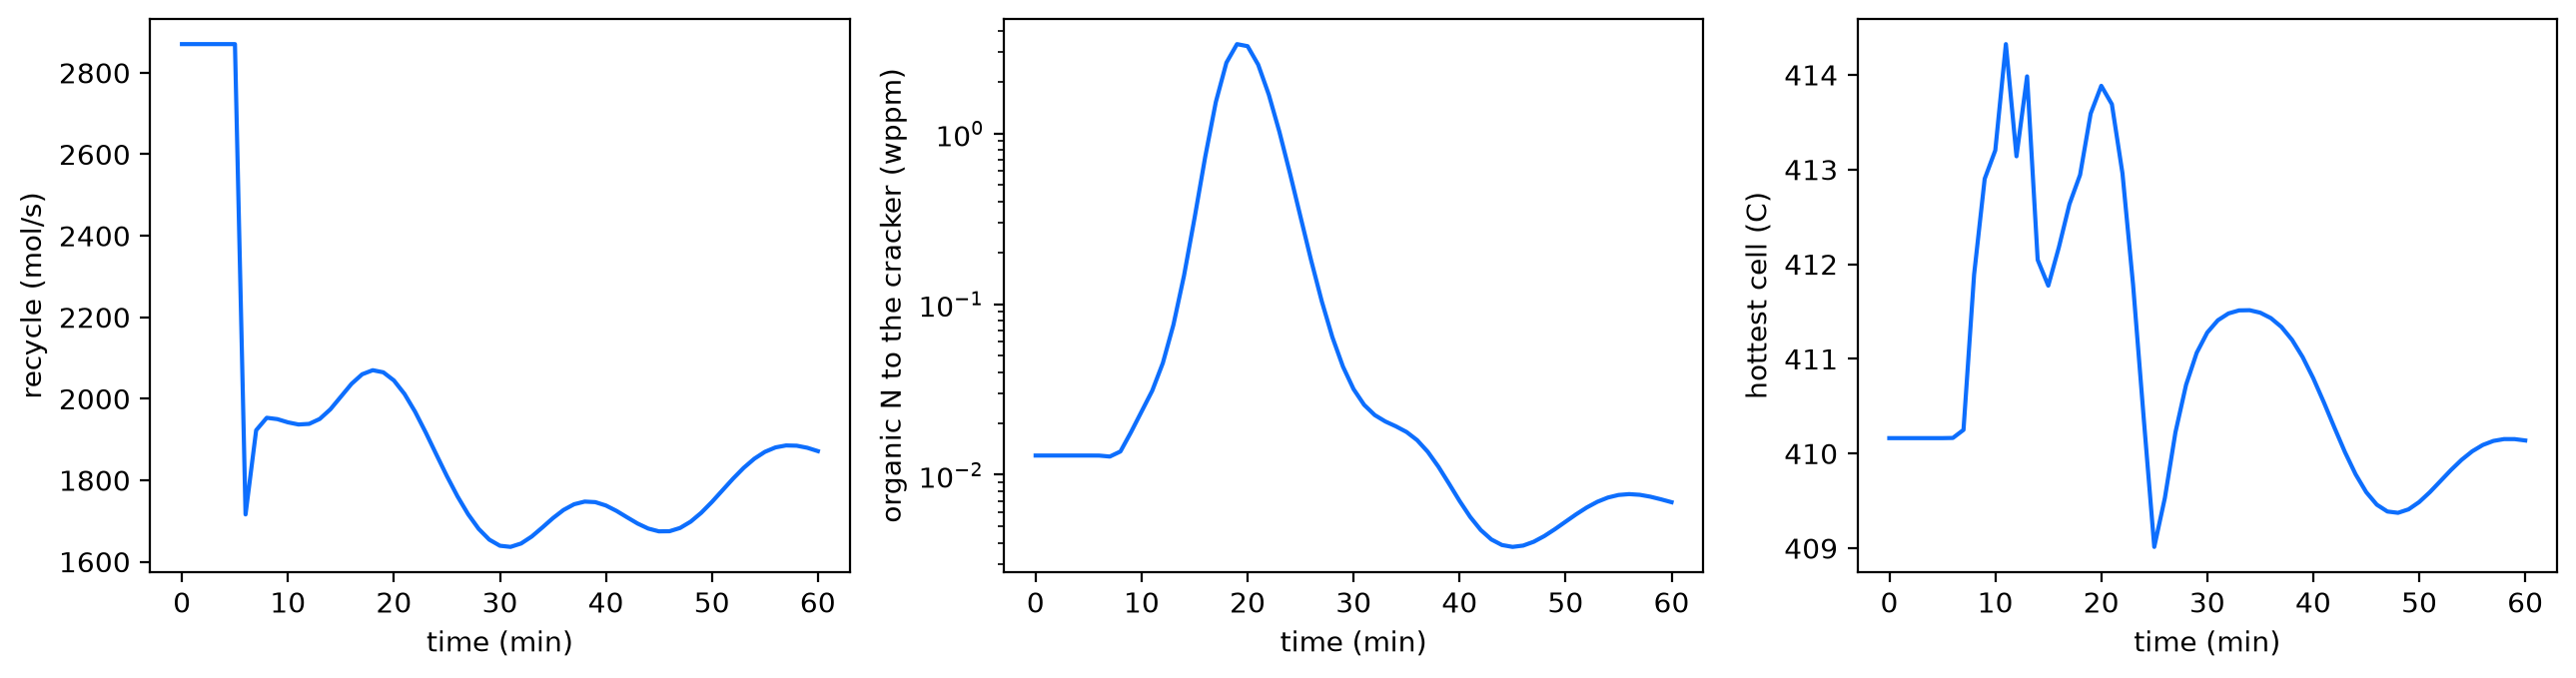

In [5]:
a = dyn.args(steps={"compressor": [(300.0, -0.5)], "T_crack": [(300.0, -10.0)]},
             ramp=R(compressor=60.0, T_crack=ramp_for_rate(10.0, 30.0 / 3600)))
t0 = time.time()
sim = dyn.simulate(3600.0, args=a, y0=y_rest, n_save=61)
tr = dyn.trajectory(sim, a, ["T_max", "conversion.per_pass", "pretreat.N_wppm", "recycle.rate"])
print(f"{time.time() - t0:.0f} s, {int(sim.info.n_steps)} steps, completed {bool(sim.info.success)}")
t = np.asarray(tr["t"]) / 60
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(t, np.asarray(tr["recycle.rate"])); ax[0].set_ylabel("recycle (mol/s)")
ax[1].plot(t, np.asarray(tr["pretreat.N_wppm"])); ax[1].set_ylabel("organic N to the cracker (wppm)"); ax[1].set_yscale("log")
ax[2].plot(t, np.asarray(tr["T_max"]) - 273.15); ax[2].set_ylabel("hottest cell (C)")
for a_ in ax: a_.set_xlabel("time (min)")
fig.tight_layout()

## 5. The margin to runaway

Rather than integrate through a runaway, ask how far the unit is from one: ramp the cracking inlets up (here 40 K at 15 K/h, a probe, not an operating move) and watch each bed's rise and how far its quench valve is from its stop. The run is capped; where it stops, the beds' rises are growing faster than the inlet -- the approach to runaway -- and the integrator's effort climbs with them.

465 s, 3000 steps, completed False; reached inlet 386.0 C


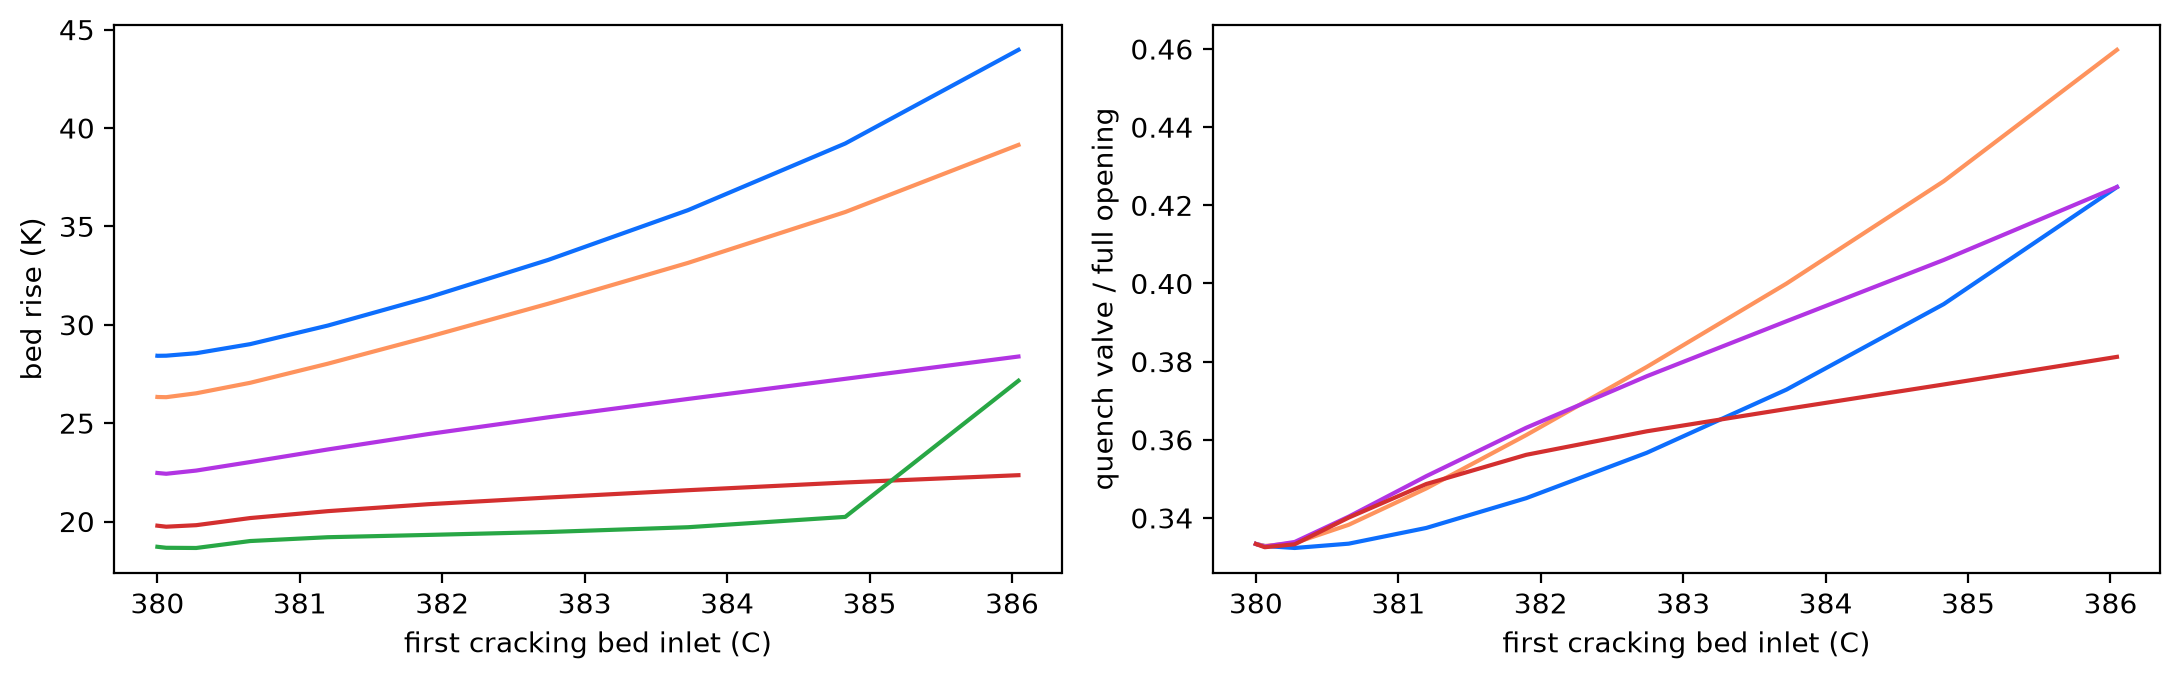

In [6]:
a = dyn.args(steps={"T_crack": [(300.0, 40.0)]}, ramp=R(T_crack=ramp_for_rate(40.0, 15.0 / 3600)))
t0 = time.time()
sim = dyn.simulate(300.0 + ramp_for_rate(40.0, 15.0 / 3600) + 1800.0, args=a, y0=y_rest, n_save=41, max_steps=3000, warn=False)
tr = dyn.trajectory(sim, a, ["T_max", "crack.T_in", "crack.T_out", "crack.quench"])
print(f"{time.time() - t0:.0f} s, {int(sim.info.n_steps)} steps, completed {bool(sim.info.success)}; "
      f"reached inlet {float(np.asarray(tr['crack.T_in'])[-1, 0]) - 273.15:.1f} C")
Tin = np.asarray(tr["crack.T_in"])[:, 0] - 273.15
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(Tin, np.asarray(tr["crack.T_out"]) - np.asarray(tr["crack.T_in"])); ax[0].set_ylabel("bed rise (K)")
ax[1].plot(Tin, np.asarray(tr["crack.quench"]) / np.asarray(dyn.crack.q_max)); ax[1].set_ylabel("quench valve / full opening")
for a_ in ax: a_.set_xlabel("first cracking bed inlet (C)")
fig.tight_layout()

## 6. What does not integrate: a full compressor trip

Even modelled as an interlock sequence -- the compressor runs down over a minute, the feed is cut to 5 % over two minutes, the heater and interstage setpoints fall 60 K over ten -- the explicit integrator stalls within minutes of the trip: with no recycle the beds lose most of their hydrogen and the heavy cuts' sulfur and nitrogen chemistry changes regime. A real unit also depressures, which this model (fixed pressures) cannot represent. The run is capped and says so.

In [7]:
a = dyn.args(steps={"compressor": [(300.0, -1.0)], "feed_rate": [(300.0, -0.95)], "T_crack": [(300.0, -60.0)],
                    "T_pretreat": [(300.0, -60.0)]},
             ramp=R(compressor=60.0, feed_rate=120.0, T_crack=600.0, T_pretreat=600.0))
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always", DynamicRunawayWarning)
    sim = dyn.simulate(1800.0, args=a, y0=y_rest, n_save=13, max_steps=3000)
for x in w:
    print("warning:", str(x.message)[:300])

## 7. The reformer with its recycle loop

`DynamicReformerTrain.from_steady(..., recycle_loop=True)` makes the separator and the recycle loop dynamic (`DynamicReformerLoop`): the separator liquid holdup, the loop's gas inventory, the compressor on the H2/HC spec and the net gas on a pressure controller. Its rest state is the steady reformer's. A partial compressor trip (to 60 % for ten minutes) cuts the hydrogen to the reactors.

141 s; RON at rest 92.501 (steady 92.501)


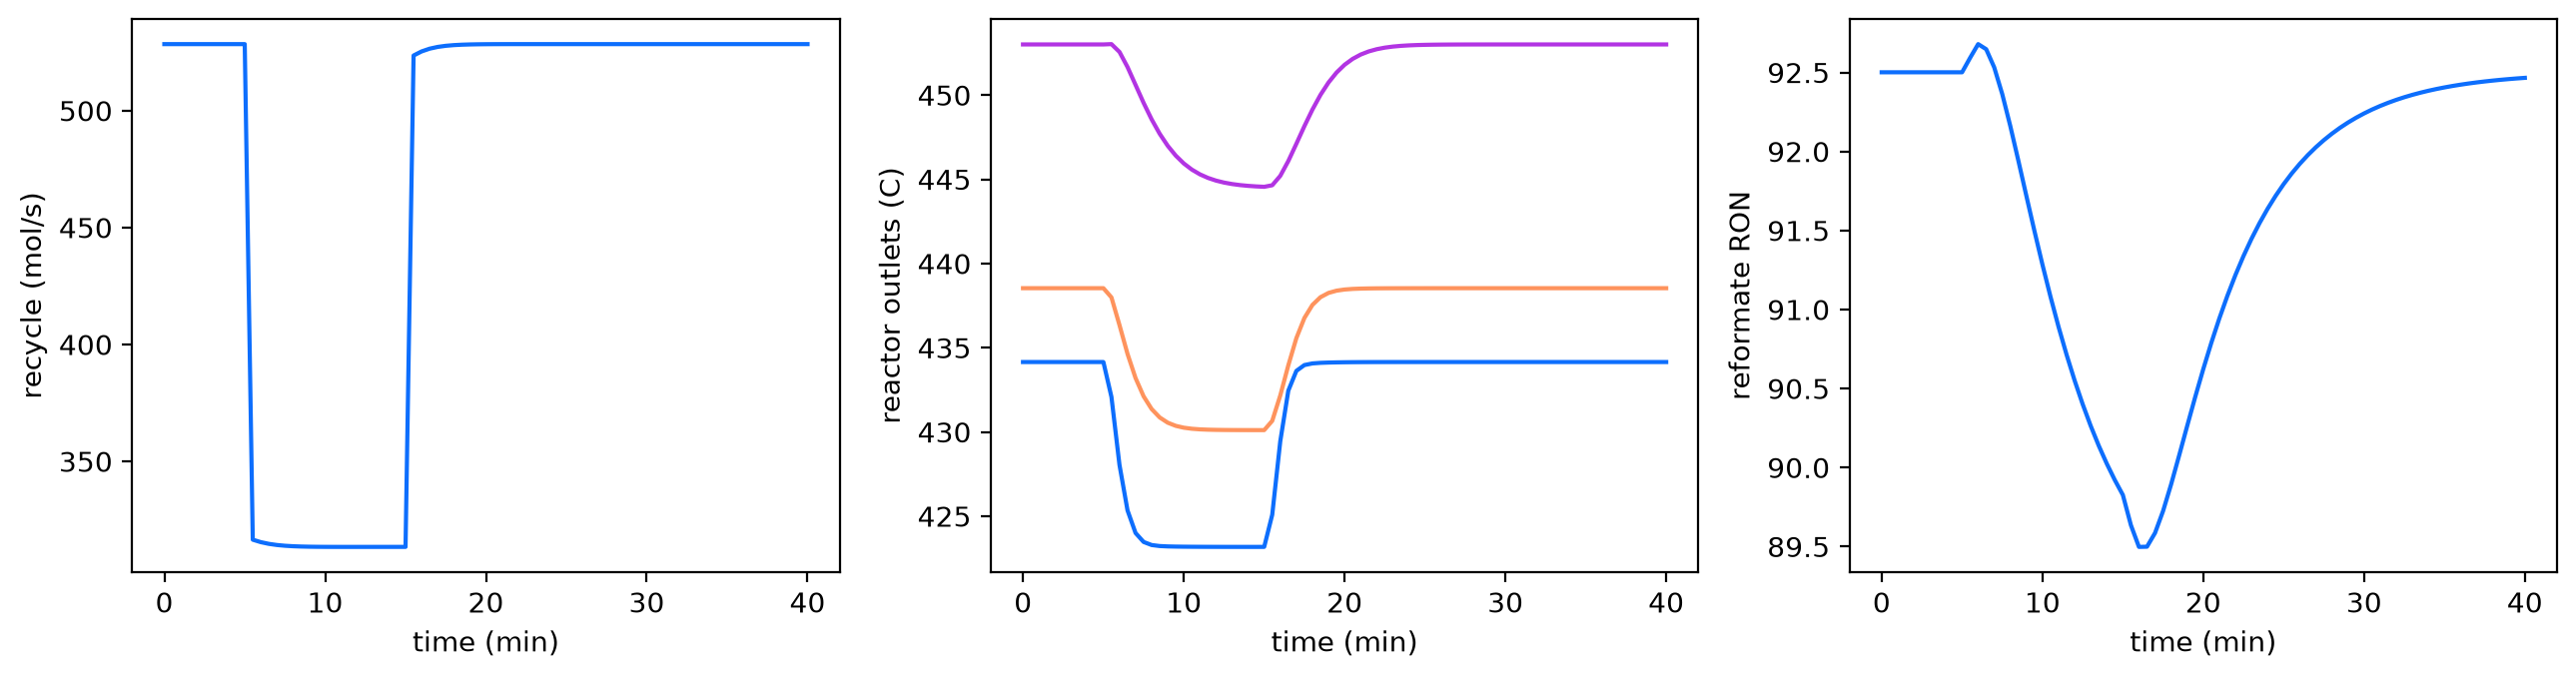

In [8]:
from difflow_refinery.reforming import CatalyticReformer, ReformerParams, lean_naphtha
naphtha = lean_naphtha()
reformer = CatalyticReformer(ReformerParams())
steady_r = reformer.solve(naphtha)
tr = DynamicReformerTrain.from_steady(reformer, naphtha, steady_r, recycle_loop=True)
t0 = time.time()
yr = tr.y0
a = tr.args(steps={"compressor": [(300.0, -0.4), (900.0, 0.4)]}, ramp=30.0)
sim = tr.simulate(2400.0, args=a, y0=yr, n_save=81)
o = tr.trajectory(sim, a, ["T_out", "reformate.RON", "recycle.rate", "h2.make"])
print(f"{time.time() - t0:.0f} s; RON at rest {float(o['reformate.RON'][0]):.3f} (steady {float(steady_r.outputs()['reformate.RON']):.3f})")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
t = np.asarray(o["t"]) / 60
ax[0].plot(t, np.asarray(o["recycle.rate"])); ax[0].set_ylabel("recycle (mol/s)")
ax[1].plot(t, np.asarray(o["T_out"]) - 273.15); ax[1].set_ylabel("reactor outlets (C)")
ax[2].plot(t, np.asarray(o["reformate.RON"])); ax[2].set_ylabel("reformate RON")
for a_ in ax: a_.set_xlabel("time (min)")
fig.tight_layout()

## What this is and is not

* The rest states are the steady units' (the hydrocracker's to the cell discretisation, the reformer loop's to round-off); element balances close at every state of a trajectory; gradients through trajectories match central differences (the numbers are in the docs' gates).
* Operator ramps, a partial loss of recycle and the approach to runaway integrate; a full compressor trip does not (section 6), and a real trip also depressures, which fixed pressures cannot show.
* The holdups, catalyst heat capacity, controller time constants, valve capacities and the alarm temperature are illustrative. A cell's gas residence time is floored at 20 s (`min_gas_tau`) so the explicit integrator steps at the liquid's and the catalyst's pace, not the gas's; that slows the gas's transit through a bed and nothing else.
* Pressures are fixed. The fractionator is the steady TBP split behind product holdups, not a column with tray dynamics. No transient here has been compared with a plant.